# 11 — Detecção facial: fluxos e qualidade da detecção

**EP · Data Science Knowledge Base | Análise e Classificação de Imagens | Notebook 11/16**

**Pré-requisitos:** Python, NumPy e fundamentos de visualização; consulte os capítulos anteriores quando necessário.

**Escopo de validação:** As células principais usam dados sintéticos ou conjuntos fornecidos pelas bibliotecas. Dependências adicionais só são necessárias nos laboratórios explicitamente opcionais.

---

> **Biblioteca pessoal de Ciência de Dados** · Análise e Classificação de Imagens · Capítulo 11/16

> **Execução:** ainda não confirmada nesta versão; reinicie o kernel e execute as células obrigatórias localmente.


### Materiais complementares

- [Guia Técnico](./reference_materials/11_deteccao_facial_pipeline.pdf)
- [Cheat Sheet](./cheat_sheets/cheat_sheet_deteccao_facial_pipeline.pdf)


## Como estudar este capítulo

1. Leia os fundamentos e consulte o Guia Técnico correspondente.
2. Reinicie o kernel e execute as células obrigatórias na sequência.
3. Confira tabelas, visualizações, saídas e limitações descritas no notebook.
4. Resolva o exercício antes de consultar a solução; execute laboratórios opcionais apenas em ambiente compatível.

**Pré-requisitos transversais:** Programação Python (01), visualização de dados (02), Estatística (03), Machine Learning (05) e Deep Learning (07), conforme o capítulo.


## Objetivos de aprendizagem

Distinguir localização, verificação e identificação com avaliação por IoU.

Ao concluir, você deverá ser capaz de **explicar a técnica**, **executar o exemplo**, **interpretar limitações** e **justificar escolhas de avaliação**.

## Fundamentos conceituais

Detecção localiza presença e bounding boxes; verificação estima se duas amostras pertencem à mesma identidade; identificação escolhe entre identidades. Uma cadeia completa inclui preparo, localização, avaliação de confiança e, quando justificado, posteriores tarefas. Para sistemas biométricos é indispensável propósito legítimo, consentimento e proteção de dados.

### Conceito matemático

$$Precision=\frac{TP}{TP+FP}$$

A fórmula expressa o mecanismo principal do capítulo. Identifique unidades, dimensões e hipóteses antes de aplicar uma implementação.

## Experimento 1 — construção e medidas

Execute em kernel limpo. Exemplos usam datasets de bibliotecas instaláveis e não requerem download de arquivos externos.

In [1]:
import numpy as np
# Caixas fictícias [x1,y1,x2,y2], sem informação biométrica.
true=np.array([10,10,30,30]);pred=np.array([15,12,31,28])
def iou(a,b):
 x1,y1=np.maximum(a[:2],b[:2]);x2,y2=np.minimum(a[2:],b[2:]);inter=max(0,x2-x1)*max(0,y2-y1)
 aa=(a[2]-a[0])*(a[3]-a[1]);bb=(b[2]-b[0])*(b[3]-b[1]);return inter/(aa+bb-inter)
print('IoU:',round(iou(true,pred),3))

IoU: 0.577


## Experimento 2 — visualização, comparação ou validação

Observe não apenas o valor obtido, mas o que o experimento **realmente demonstra**.

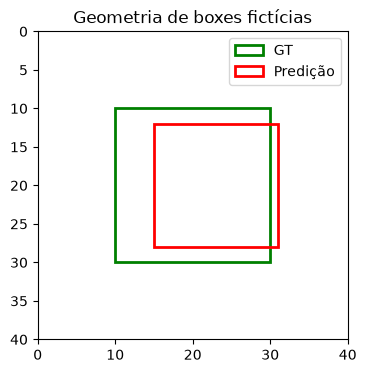

In [2]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
fig,ax=plt.subplots(figsize=(4,4));ax.set_xlim(0,40);ax.set_ylim(40,0)
for b,color,name in [(true,'green','GT'),(pred,'red','Predição')]:
 ax.add_patch(Rectangle((b[0],b[1]),b[2]-b[0],b[3]-b[1],fill=False,edgecolor=color,label=name,linewidth=2))
ax.legend();ax.set_title('Geometria de boxes fictícias');plt.show()

## Interpretação técnica

Um detector pode obter IoU razoável em uma imagem e falhar sistematicamente em outras condições.

### Conexão com o acervo

Em vez de repetir capítulos de SVM, PCA, métricas e backpropagation, este notebook concentra a aplicação e limitações **em imagens**. Revisite as Disciplinas 05 e 07 para demonstrações matemáticas mais extensas.

## Exercício resolvido

**Problema:** Um resultado de detecção informa o nome da pessoa?

**Resolução comentada:** Não. Detectar uma face não equivale a reconhecer identidade.

**Para praticar:** modifique um parâmetro do exemplo, registre a hipótese antes de executar e compare resultado, qualidade visual e custo computacional.

## Erros comuns e limitações

Fotos históricas de alunos ou participantes não devem ser redistribuídas sem autorização.

- Nunca ajustar parâmetros em cima do conjunto de teste final.
- Não confundir demonstração com validação científica completa.
- Documentar versões, fontes de dados e condições de execução.
- Não redistribuir fotografias de rostos ou datasets históricos sem licença e autorização.

## Consulta rápida

- **Pergunta-chave:** Distinguir localização, verificação e identificação com avaliação por IoU.
- **Mecanismo:** Detecção localiza presença e bounding boxes; verificação estima se duas amostras pertencem à mesma identidade; identificação escolhe entre identidades.
- **Equação:** $Precision=\frac{TP}{TP+FP}$
- **Verificação:** interpretar formato dos dados, hipótese e saída antes de utilizar em um projeto.

### Referências de estudo

- Apresentações originais da disciplina (PDF consolidado).
- Documentação: [scikit-image](https://scikit-image.org/docs/stable/), [OpenCV](https://docs.opencv.org/4.x/), [scikit-learn](https://scikit-learn.org/stable/), conforme o capítulo.
- Para CNNs: [Keras](https://keras.io/).

## Aprofundamento v2 — auditoria e aplicação

**Ponto de atenção deste capítulo:** precision/recall de detecção. Este complemento não substitui as seções e exemplos anteriores.

**Verificação conceitual.** Explique, com suas palavras, em qual etapa do fluxo de trabalho o tema **precision/recall de detecção** pode produzir conclusões enganosas. Indique um indicador observável, um teste mínimo e uma limitação do procedimento.

**Exercício de extensão.** Reproduza o experimento central deste notebook alterando **um parâmetro por vez**. Compare com uma linha de base simples, reporte a variação da métrica pertinente e justifique o resultado. Quando houver treino/teste, qualquer etapa que aprenda parâmetros deve usar apenas o treino.

**Checklist de conclusão:** (1) entradas identificadas; (2) sementes registradas; (3) saídas interpretadas; (4) premissas explicitadas; (5) dados originais não sobrescritos.


### Exercício resolvido — protocolo mínimo de validação

**Enunciado.** Proponha uma comparação para **precision/recall de detecção** sem contaminar a avaliação.

**Solução orientadora.** Defina uma hipótese falsificável, escolha um baseline simples, fixe uma divisão adequada ao problema, altere uma única decisão metodológica e compare métricas no conjunto reservado. Não transforme exemplos sintéticos em conclusões sobre populações reais. Documente a configuração e os casos de falha. Quando o tema não envolver predição, substitua o baseline por uma implementação de referência e compare correção, cobertura e custo.
